<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/HierarchicalCosine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Hierarchical Clustering - Cosine (Agglomerative)

Metode **Agglomerative (bottom-up)**: tiap titik mulai sebagai cluster sendiri,
lalu dua cluster terdekat digabung berulang sampai satu cluster. Prosesnya
digambar sebagai **dendrogram** untuk memilih jumlah cluster (analogi Elbow Method).

**Parameter (sesuai outline UTS):**
* `n_clusters = 3` - **disamakan** dengan K-Means & DBSCAN (fair comparison).
* `linkage = 'average'` - dipakai untuk **ketiga metrik** (outline: satu linkage
  untuk ketiga metrik; Ward hanya untuk euclidean sehingga tidak dipakai).
* `metric = 'cosine'` - jarak antar-titik.
* Evaluasi khusus hierarchical: **cophenetic correlation** (seberapa baik
  dendrogram mempertahankan jarak asli).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import pdist
import time
import tracemalloc
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
print("Library siap.")

Library siap.


In [2]:
df = pd.read_csv('properti_multi_kota.csv')
print("Shape awal:", df.shape)
df.head()

Shape awal: (64650, 8)


,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08


In [3]:
# ============================================
# PREPROCESSING UNIVERSAL - dataset baru
# ============================================

# 1. Hapus duplikat (hasil scraping dari banyak sumber)
before = len(df)
df = df.drop_duplicates()
print(f"[1] Hapus duplikat       : {before} -> {len(df)}")

# 2. Hapus outlier & nilai tidak wajar (error scraping)
before = len(df)
df = df[(df['luas_m2'] >= 10) & (df['luas_m2'] <= 2000)]
df = df[(df['luas_bangunan'].isna()) |
        ((df['luas_bangunan'] >= 10) & (df['luas_bangunan'] <= 2000))]
df = df[(df['harga'] >= 50_000_000) & (df['harga'] <= 100_000_000_000)]
df = df[df['jumlah_kamar'].isna() | (df['jumlah_kamar'] <= 20)]
df = df[df['jumlah_kamar_mandi'].isna() | (df['jumlah_kamar_mandi'] <= 20)]
print(f"[2] Hapus outlier        : {before} -> {len(df)}")

# 3. Perbaiki usia_bangunan: sebagian sumber menyimpan TAHUN bangunan
#    (misal 2020), bukan usia. Nilai > 100 dikonversi: usia = 2026 - tahun.
mask_tahun = df['usia_bangunan'] > 100
df.loc[mask_tahun, 'usia_bangunan'] = 2026 - df.loc[mask_tahun, 'usia_bangunan']
df.loc[~df['usia_bangunan'].between(0, 100) & df['usia_bangunan'].notna(),
       'usia_bangunan'] = np.nan
print(f"[3] Konversi tahun->usia : {mask_tahun.sum()} baris dikonversi")

# 4. Isi missing values dengan median
FEATURES = ['luas_m2', 'luas_bangunan', 'jumlah_kamar',
            'jumlah_kamar_mandi', 'usia_bangunan', 'harga']
for col in FEATURES:
    df[col] = df[col].fillna(df[col].median())
print(f"[4] Missing values diisi : {df[FEATURES].isnull().sum().sum()} tersisa")

# 5. Sampling 15.000 data (reproducible) - dataset asli ~56 ribu,
#    sampling agar Hierarchical & DBSCAN layak dijalankan.
df = df.sample(n=15000, random_state=42).reset_index(drop=True)
print(f"[5] Sampling             : 15.000 data (random_state=42)")

# 6. Scaling (StandardScaler untuk euclidean/manhattan)
X = df[FEATURES].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Khusus cosine: L2 normalization (setiap vektor jadi unit vector)
X_cosine = normalize(X_scaled, norm='l2')

print(f"[6] Data siap clustering : {X_scaled.shape}")
print(f"[7] Fitur                : {FEATURES}")

[1] Hapus duplikat       : 64650 -> 57494
[2] Hapus outlier        : 57494 -> 56170
[3] Konversi tahun->usia : 2757 baris dikonversi
[4] Missing values diisi : 0 tersisa
[5] Sampling             : 15.000 data (random_state=42)
[6] Data siap clustering : (15000, 6)
[7] Fitur                : ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'usia_bangunan', 'harga']


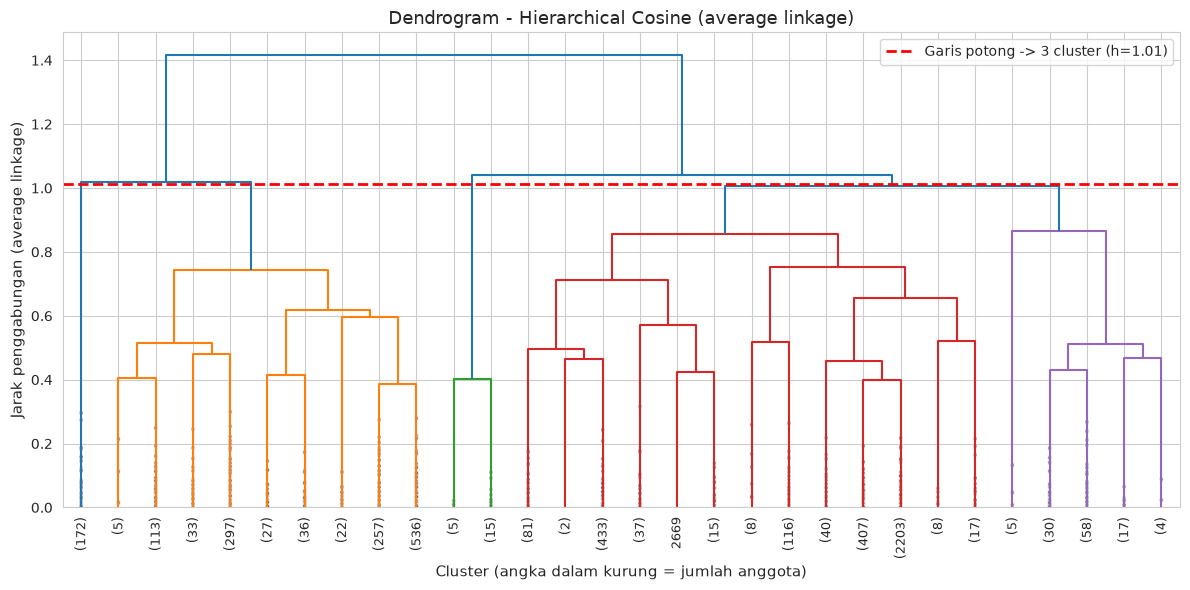

Ketinggian 6 penggabungan terakhir & lompatannya:
  h = 0.8560   (lompatan: 0.0000)
  h = 0.8653   (lompatan: 0.0093)
  h = 1.0078   (lompatan: 0.1425)
  h = 1.0184   (lompatan: 0.0106)
  h = 1.0401   (lompatan: 0.0218)
  h = 1.4165   (lompatan: 0.3764)



Cophenetic correlation (Cosine): 0.8607
   (makin dekat 1 = dendrogram makin setia pada jarak asli)

>> Dendrogram dipotong pada ketinggian yang menghasilkan 3 cluster,
   disamakan dengan K-Means (k=3) & DBSCAN (tuning eps).


In [4]:
# ============================================
# DENDROGRAM - pemilihan jumlah cluster
# Dihitung pada subsample 5.000 agar linkage & cophenetic layak dihitung
# (matriks jarak 15.000x15.000 terlalu besar). Clustering final tetap 15.000.
# ============================================
rng = np.random.RandomState(42)
sub_idx = rng.choice(len(X_cosine), 5000, replace=False)
X_sub = X_cosine [sub_idx]

Z = linkage(X_sub, method='average', metric='cosine')

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90,
           leaf_font_size=9, show_contracted=True)
cut_height = (Z[-4, 2] + Z[-3, 2]) / 2
plt.axhline(y=cut_height, color='red', linestyle='--', linewidth=2,
            label=f'Garis potong -> 3 cluster (h={cut_height:.2f})')
plt.xlabel('Cluster (angka dalam kurung = jumlah anggota)', fontsize=11)
plt.ylabel('Jarak penggabungan (average linkage)', fontsize=11)
plt.title('Dendrogram - Hierarchical Cosine (average linkage)', fontsize=13)
plt.legend(); plt.tight_layout(); plt.show()

print("Ketinggian 6 penggabungan terakhir & lompatannya:")
heights = Z[-6:, 2]
for i, h in enumerate(heights):
    gap = heights[i] - heights[i-1] if i > 0 else 0.0
    print(f"  h = {h:.4f}   (lompatan: {gap:.4f})")

# Cophenetic correlation: kualitas dendrogram mempertahankan jarak asli
coph, _ = cophenet(Z, pdist(X_sub, metric='cosine'))
print(f"\nCophenetic correlation (Cosine): {coph:.4f}")
print("   (makin dekat 1 = dendrogram makin setia pada jarak asli)")
print("\n>> Dendrogram dipotong pada ketinggian yang menghasilkan 3 cluster,")
print("   disamakan dengan K-Means (k=3) & DBSCAN (tuning eps).")

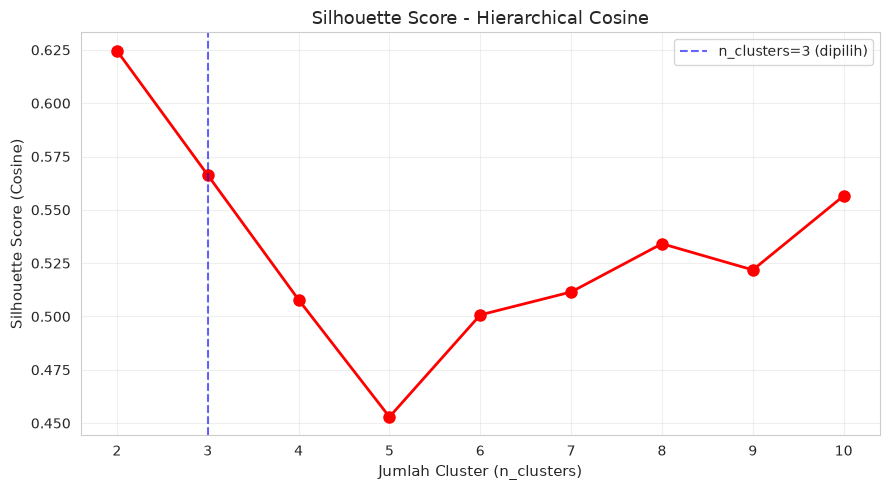

Silhouette Score per n_clusters:
  n_clusters=2: 0.6246
  n_clusters=3: 0.5663
  n_clusters=4: 0.5079
  n_clusters=5: 0.4529
  n_clusters=6: 0.5007
  n_clusters=7: 0.5115
  n_clusters=8: 0.5341
  n_clusters=9: 0.5218
  n_clusters=10: 0.5566

>> Tetap dipakai n_clusters=3 agar SAMA di semua metode (fair comparison).


In [5]:
# Validasi: silhouette untuk n_clusters = 2 sampai 10
K_RANGE = range(2, 11)
sil_scores = []
for k in K_RANGE:
    agg = AgglomerativeClustering(n_clusters=k, metric='cosine', linkage='average')
    labels_tmp = agg.fit_predict(X_cosine)
    sil_scores.append(silhouette_score(X_cosine, labels_tmp, metric='cosine'))

plt.figure(figsize=(9, 5))
plt.plot(K_RANGE, sil_scores, 'ro-', linewidth=2, markersize=8)
plt.axvline(x=3, color='blue', linestyle='--', alpha=0.6, label='n_clusters=3 (dipilih)')
plt.xlabel('Jumlah Cluster (n_clusters)', fontsize=11)
plt.ylabel('Silhouette Score (Cosine)', fontsize=11)
plt.title('Silhouette Score - Hierarchical Cosine', fontsize=13)
plt.xticks(K_RANGE); plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

print("Silhouette Score per n_clusters:")
for k, s in zip(K_RANGE, sil_scores):
    print(f"  n_clusters={k}: {s:.4f}")
print("\n>> Tetap dipakai n_clusters=3 agar SAMA di semua metode (fair comparison).")

In [6]:
# ============================================
# PARAMETER & TRAINING
# ============================================
N_CLUSTERS = 3        # sama dengan k=3 (K-Means) & target 3 cluster (DBSCAN)
LINKAGE = 'average'   # satu linkage untuk ketiga metrik (outline)

tracemalloc.start()
start = time.time()
agg = AgglomerativeClustering(n_clusters=N_CLUSTERS, metric='cosine', linkage=LINKAGE)
labels = agg.fit_predict(X_cosine)
exec_time = time.time() - start
_, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()

df['cluster'] = labels
print("="*55); print("HASIL HIERARCHICAL (COSINE)"); print("="*55)
print(f"Jumlah cluster : {N_CLUSTERS}")
print(f"Linkage        : {LINKAGE}")
print(f"Waktu eksekusi : {exec_time*1000:.2f} ms")
print(f"Peak memory    : {peak/1024:.2f} KB")
print("\nDistribusi cluster:")
print(df['cluster'].value_counts().sort_index())

HASIL HIERARCHICAL (COSINE)
Jumlah cluster : 3
Linkage        : average
Waktu eksekusi : 6092.88 ms
Peak memory    : 988709.58 KB

Distribusi cluster:
cluster
0    10339
1     4200
2      461
Name: count, dtype: int64


In [7]:
print("Rata-rata fitur per cluster:")
print(df.groupby('cluster')[FEATURES].mean().round(2))

Rata-rata fitur per cluster:
         luas_m2  luas_bangunan  jumlah_kamar  jumlah_kamar_mandi  \
cluster                                                             
0         100.77          61.26          2.05                1.33   
1         315.74         239.63          4.20                3.29   
2         185.36         125.92          3.31                2.55   

         usia_bangunan         harga  
cluster                               
0                 9.79  7.852064e+08  
1                 9.90  3.594210e+09  
2                24.93  1.987036e+09  


In [8]:
print("\nDistribusi lokasi per cluster (10 lokasi terbanyak):")
top_lokasi = df['lokasi'].value_counts().head(10).index
print(pd.crosstab(df['cluster'], df.loc[df['lokasi'].isin(top_lokasi), 'lokasi']))

print("\nDistribusi sumber data per cluster (10 sumber terbanyak):")
top_sumber = df['sumber'].value_counts().head(10).index
print(pd.crosstab(df['cluster'], df.loc[df['sumber'].isin(top_sumber), 'sumber']))


Distribusi lokasi per cluster (10 lokasi terbanyak):
lokasi   Bekasi  Depok  Kabupaten Bandung  Kabupaten Bekasi  Kabupaten Bogor  \
cluster                                                                        
0           325    232                378               415              490   
1           122    109                 34                44               38   
2            50     46                  0                 0                0   

lokasi   Kabupaten Sidoarjo  Kabupaten Tangerang  Semarang  Surabaya  \
cluster                                                                
0                       388                  333       253       189   
1                        43                  120        96       207   
2                         0                    0         3        44   

lokasi   Tangerang Selatan  
cluster                     
0                      248  
1                      185  
2                        3  

Distribusi sumber data per cluster (10

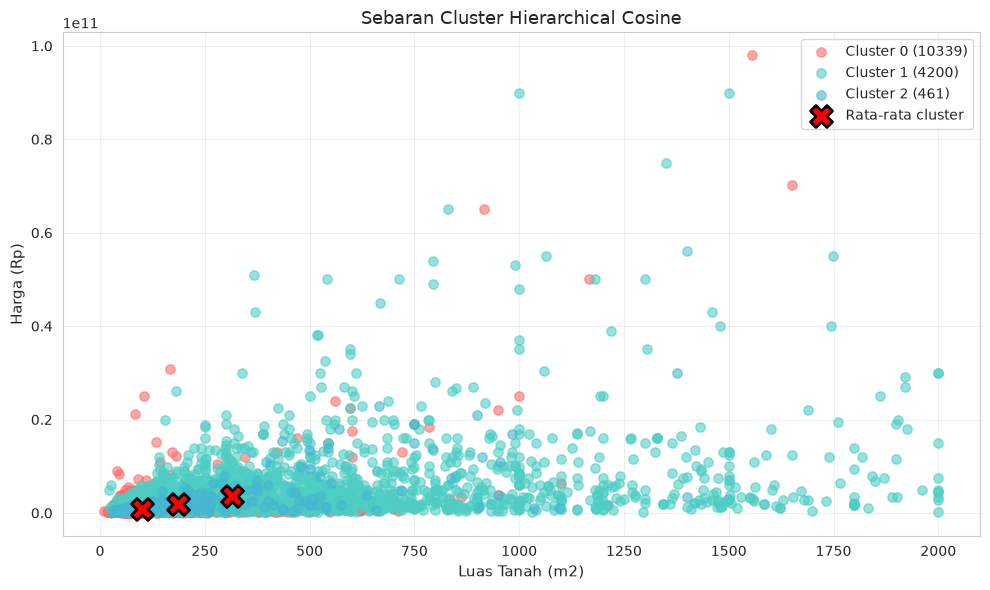

In [9]:
plt.figure(figsize=(10, 6))
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']
for i, label in enumerate(sorted(df['cluster'].unique())):
    subset = df[df['cluster'] == label]
    plt.scatter(subset['luas_m2'], subset['harga'], s=45, alpha=0.6,
                c=colors[i % len(colors)], label=f'Cluster {label} ({len(subset)})')
means = df.groupby('cluster')[['luas_m2', 'harga']].mean()
plt.scatter(means['luas_m2'], means['harga'], c='red', marker='X', s=250,
            edgecolor='black', linewidth=2, label='Rata-rata cluster', zorder=5)
plt.xlabel('Luas Tanah (m2)', fontsize=11)
plt.ylabel('Harga (Rp)', fontsize=11)
plt.title('Sebaran Cluster Hierarchical Cosine', fontsize=13)
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

In [10]:
# ============================================
# EVALUASI (sesuai outline UTS)
# ============================================
sil_final = silhouette_score(X_cosine, df['cluster'], metric='cosine')
dbi_final = davies_bouldin_score(X_scaled, df['cluster'])
# cophenetic dihitung di cell dendrogram (subsample), disalin ke ringkasan

print(f"Silhouette Score (Cosine)   : {sil_final:.4f}  (makin besar makin bagus)")
print(f"Davies-Bouldin Index (Euclidean): {dbi_final:.4f}  (makin kecil makin bagus)")
print(f"Cophenetic correlation          : {coph:.4f}  (kualitas dendrogram)")
print(f"ARI / NMI : -  (dataset tidak memiliki label ground truth)")

Silhouette Score (Cosine)   : 0.5663  (makin besar makin bagus)
Davies-Bouldin Index (Euclidean): 1.1404  (makin kecil makin bagus)
Cophenetic correlation          : 0.8607  (kualitas dendrogram)
ARI / NMI : -  (dataset tidak memiliki label ground truth)


In [11]:
hasil = {
    'Metode'              : 'Hierarchical',
    'Distance Metric'     : 'Cosine',
    'Jumlah Cluster'      : N_CLUSTERS,
    'Jumlah Noise'        : 0,
    '% Noise'             : 0.0,
    'Waktu Eksekusi (ms)' : round(exec_time * 1000, 2),
    'Silhouette'          : round(sil_final, 4),
    'DBI (Euclidean)'     : round(dbi_final, 4),
    'Cophenetic'          : round(coph, 4),
    'ARI'                 : '-',
    'NMI'                 : '-',
    'Parameter'           : 'n_clusters=3, linkage=average'
}

tabel = pd.DataFrame([hasil])
print("="*60)
print("RINGKASAN METRIK - HIERARCHICAL COSINE")
print("="*60)
tabel.T

RINGKASAN METRIK - HIERARCHICAL COSINE


,0
Metode,Hierarchical
Distance Metric,Cosine
Jumlah Cluster,3
Jumlah Noise,0
% Noise,0.0
Waktu Eksekusi (ms),6092.88
Silhouette,0.5663
DBI (Euclidean),1.1404
Cophenetic,0.8607
ARI,-
